# BTD: separate a multichannel image

A multichannel image (for example a multispectral image) records several numbers per pixel,
one per channel. When the scene is made of a few materials, each with its own spatial
layout and its own spectrum, the image is a sum of terms *spatial map × spectrum*. This is
the **BTD** model with rank-(L, L, 1) terms (see [BTD](../models/btd.md)).

This tutorial builds such an image, then recovers its terms with
{class}`~pybbtd.btd.BTD` and the ALS solver.

## The data

60 × 80 pixels and 6 channels. There are R = 3 terms; each spatial map is a sum of L = 2
blobs (rank 2), and each spectrum is 6 random positive numbers. We add 1% noise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pybbtd import BTD
from pybbtd.btd import factors_to_tensor, spatial_maps
from pybbtd.datasets import make_blob_factors
from pybbtd.visualization import plot_error

np.random.seed(0)
n_rows, n_cols, n_channels = 60, 80, 6
R, L = 3, 2

A0, B0 = make_blob_factors(n_rows, n_cols, R, L, seed=0)  # spatial maps
C0 = np.random.rand(n_channels, R)  # one spectrum per term

model = BTD((n_rows, n_cols, n_channels), R, L)
T0 = factors_to_tensor(A0, B0, C0, model.get_constraint_matrix())
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)
T.shape

(60, 80, 6)

The true spatial maps, and the 6 channels of the data. Every channel is a mix of the
three maps, weighted by the spectra:

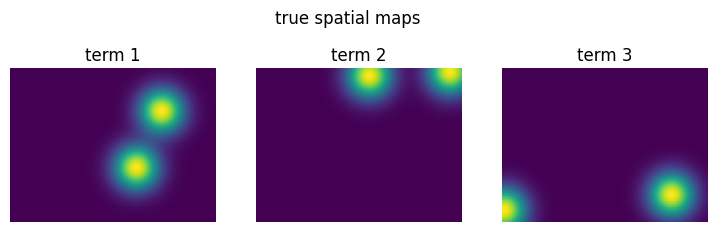

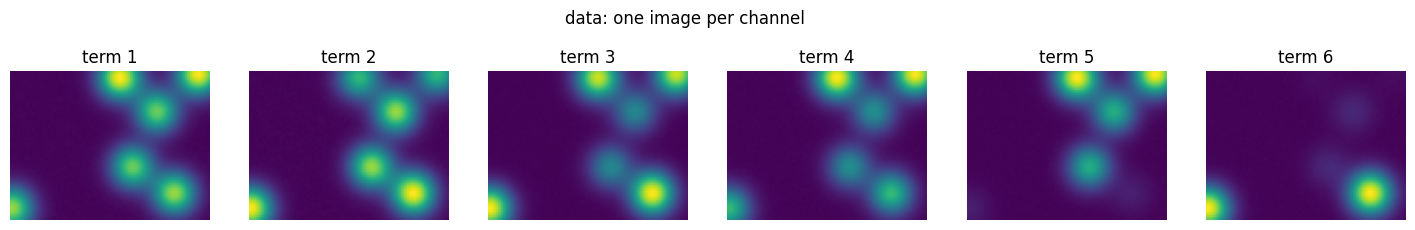

In [2]:
def show_maps(maps, title):
    """Plot one image per term, scaled so its strongest pixel is +1."""
    fig, axes = plt.subplots(1, len(maps), figsize=(3 * len(maps), 2.8))
    for r, (ax, m) in enumerate(zip(axes, maps, strict=True)):
        ax.imshow(m / m.flat[np.abs(m).argmax()], cmap="viridis")
        ax.set_title(f"term {r + 1}")
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_maps(spatial_maps(A0, B0, L), "true spatial maps")
show_maps(np.moveaxis(T, 2, 0), "data: one image per channel")

## Fit the model

First check that these sizes and ranks guarantee a unique answer
(see [Ranks and uniqueness](../guides/ranks-and-uniqueness.md)):

In [3]:
model.check_uniqueness()

True

Fit with two different starting points: random factors, and factors taken from the
singular value decomposition (SVD) of the data.

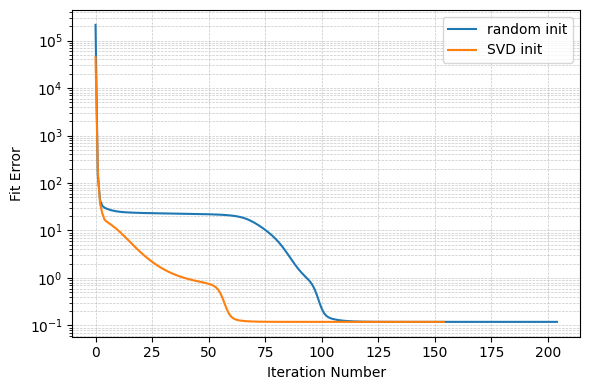

In [4]:
model.fit(T, init="random", max_iter=3000, rel_tol=1e-10, abs_tol=0)
random_init_error = model.fit_error

model.fit(T, init="svd", max_iter=3000, rel_tol=1e-10, abs_tol=0)
svd_init_error = model.fit_error

plot_error([random_init_error, svd_init_error], labels=["random init", "SVD init"])

Both runs reach the same error. ALS can also stop at a poorer solution from some starting
points; comparing the final errors of a few runs reveals it
(see [Initialization and convergence](../guides/fitting.md)).

## Check the result

The recovered maps match the true ones. The terms can come out in any order, and a map can
be scaled, even by a negative number, as long as its spectrum is scaled by the inverse.

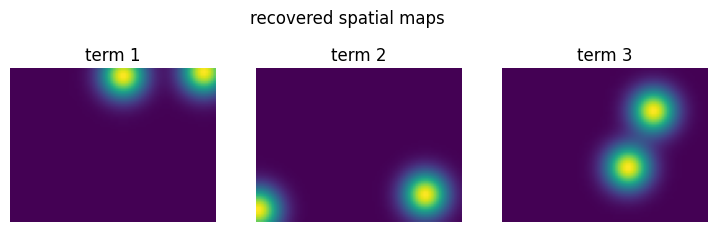

In [5]:
A, B, C = model.factors
show_maps(spatial_maps(A, B, L), "recovered spatial maps")

The fitted tensor is closer to the clean image `T0` than the noisy data are, which were
1% away from it:

In [6]:
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.0016445088639527052)